In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np

from tqdm import tqdm
from matplotlib import pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# DATASET

In [2]:
from sklearn.datasets import load_breast_cancer

dataset = load_breast_cancer()
print(dataset.DESCR)

X = dataset.data
y = dataset.target

print("SAMPLE:\n")
print(X[0])
print("LABEL:\n")
print(y[0])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

TRAIN SET shape: (455, 30)
TEST SET shape:  (114, 30)


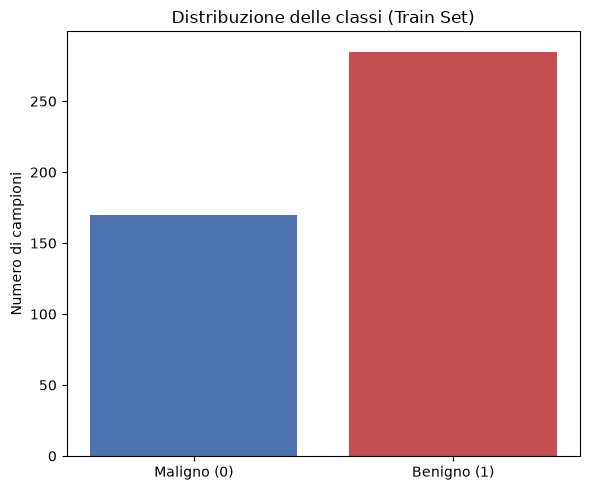

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"TRAIN SET shape: {X_train.shape}")
print(f"TEST SET shape:  {X_test.shape}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 32
train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

plt.figure(figsize=(6, 5))

classes, counts = np.unique(y_train, return_counts=True)
plt.bar(['Maligno (0)', 'Benigno (1)'], counts, color=['#4C72B0', '#C44E52'])
plt.title("Distribuzione delle classi (Train Set)")
plt.ylabel("Numero di campioni")


plt.tight_layout()
plt.show()

# PARAMETRI

In [4]:
EPOCHS = 10
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


# MODELLO

In [5]:
model = nn.Sequential(
            nn.Linear(X_train.shape[1],8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid())
model.to(DEVICE)
model

Sequential(
  (0): Linear(in_features=30, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
  (3): Sigmoid()
)

In [6]:
criterion = nn.BCELoss()

$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$

In [7]:
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, betas=(0.9, 0.999), eps=1e-7)

$ADAM\ OPTIMIZER$

$\overrightarrow{w}^{\ (0)} = INIT;\quad \overrightarrow{m}^{\ (0)}=0;\quad \overrightarrow{v}^{\ (0)}=0$

$for \quad t=0 \quad to \quad T-1 \quad do$

$\qquad SELECT \quad (\overrightarrow{x}_i,y_i)\in S;$

$\qquad \vec g^{(t)} = \nabla_w \mathcal{L}(\vec w^{(t)})$

$\qquad \overrightarrow{m}^{\ (t+1)} = \beta_1\cdot\overrightarrow{m}^{\ (t)}+(1-\beta_1)\cdot\overrightarrow{g}^{\ (t)};$

$\qquad \overrightarrow{v}^{\ (t+1)} = \beta_2\cdot\overrightarrow{v}^{\ (t)}+(1-\beta_2)\cdot\left(\overrightarrow{g}^{\ (t)}\right)^2;$

$\qquad for \quad j=0 \quad to \quad |W| - 1 \quad do:$

$\qquad \qquad w^{(t+1)}_j = w^{(t)}_j - \eta\cdot\frac{1}{\sqrt{v^{(t+1)}_j}+\epsilon}\cdot m^{(t+1)}_j$

$\quad$



$NOTA:\ ADAM\ USA\ UNA\ CORREZIONE\ DEL\ BIAS:\hat m = m/(1-\beta_1^{t+1})$ e $\hat v = v/(1-\beta_2^{t+1})$


# ADDESTRAMENTO

In [8]:
for epoch in range(EPOCHS):
    total_loss = 0
    correct = 0
    total = 0
    
    for samples, labels in tqdm(train_loader):
        optimizer.zero_grad() # Azzera i gradienti del calcolati al passo precedente
        
        samples = samples.to(DEVICE)
        labels = labels.to(DEVICE)
        
        outputs = model(samples)
        loss = criterion(outputs, labels)
        
        loss.backward() # Esegue la backpropagation
        optimizer.step() # Aggiorna i pesi della rete
        
        # Accumula la perdita totale
        total_loss += loss.item()
        

    # Stampa le metriche di training
    train_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {train_loss:.4f}")

# filename = "TDB"
# torch.save(model.state_dict(), filename)
#model = torch.load(filename, weights_only=False)
#model.eval()

100%|██████████| 15/15 [00:00<00:00, 34.50it/s]


Epoch [1/10], Loss: 0.7104


100%|██████████| 15/15 [00:00<00:00, 308.57it/s]


Epoch [2/10], Loss: 0.6406


100%|██████████| 15/15 [00:00<00:00, 343.90it/s]


Epoch [3/10], Loss: 0.5824


... (10 outputs left out)

100%|██████████| 15/15 [00:00<00:00, 337.89it/s]


Epoch [9/10], Loss: 0.3236


100%|██████████| 15/15 [00:00<00:00, 316.33it/s]

Epoch [10/10], Loss: 0.2862


# VALUTAZIONE

* **TP (True Positive – Veri Positivi):** I casi in cui il modello predice correttamente la classe positiva (es. un'email di spam classificata effettivamente come spam).
* **TN (True Negative – Veri Negativi):** I casi in cui il modello predice correttamente la classe negativa (es. un'email legittima lasciata nella posta in arrivo).
* **FP (False Positive – Falsi Positivi):** I casi in cui il modello predice erroneamente la classe positiva mentre la realtà è negativa, noti anche come *errori di I tipo* (es. un'email legittima finita per sbaglio nello spam).
* **FN (False Negative – Falsi Negativi):** I casi in cui il modello predice erroneamente la classe negativa mentre la realtà è positiva, noti anche come *errori di II tipo* (es. un'email di spam non rilevata dal filtro).

\
$$ACCURACY = \frac{TP+TN}{TP+TN+FP+FN}$$
\
$$PRECISION = \frac{TP}{TP+FP}$$
\
$$RECALL = \frac{TP}{TP+FN}$$
\
$$F1 = 2 \cdot \frac{PRECISION \cdot RECALL}{PRECISION + RECALL} = \frac{2TP}{2TP+FP+FN}$$

              precision    recall  f1-score   support

   malignant       0.86      0.90      0.88        42
      benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



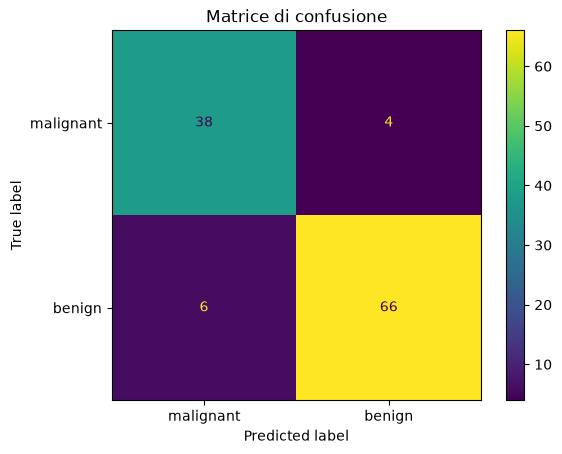

In [9]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():  # Nessun calcolo dei gradienti in valutazione
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(inputs)

        predicted = (outputs > 0.5).float()

        all_preds.append(predicted.cpu())
        all_labels.append(labels.cpu())

y_pred = torch.cat(all_preds).squeeze().numpy().astype(int)
y_true = torch.cat(all_labels).squeeze().numpy().astype(int)

print(classification_report(y_true, y_pred, target_names=dataset.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=dataset.target_names).plot()
plt.title("Matrice di confusione")
plt.show()